In [2]:
# Cell 1: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Visualization settings
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Cell 2: Load and Inspect Data
file_path = "data_Property_Transaction/property_transactions_1750066258149.xlsx"
df = pd.read_excel(file_path)

# Basic inspection
print("="*50)
print("DATA SHAPE AND COLUMNS")
print("="*50)
print(f"Shape: {df.shape}")
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 3 rows:")
display(df.head(3))

DATA SHAPE AND COLUMNS
Shape: (10000, 17)

Columns:
['Sr.No.', 'PROPERTY UID', 'PROPERTY NAME', 'TRANSACTION DATE', 'TRANSACTION TYPE', 'TRANSACTION SOURCE', 'VALUE (SAR)', 'TRANSACTION AREA (sqm)', 'BUILT UP AREA (sqm)', 'PROPERTY TRANSACTION RATE (SAR/sqm)', 'BLOCK', 'NEIGHBORHOOD', 'ZONE', 'PROPERTY TYPE ESTATER', 'PROPERTY TYPE AS PER GOVERNMENT RECORD', 'TRANSACTION ID', 'OUTLIER']

First 3 rows:


,Sr.No.,PROPERTY UID,PROPERTY NAME,TRANSACTION DATE,TRANSACTION TYPE,TRANSACTION SOURCE,VALUE (SAR),TRANSACTION AREA (sqm),BUILT UP AREA (sqm),PROPERTY TRANSACTION RATE (SAR/sqm),BLOCK,NEIGHBORHOOD,ZONE,PROPERTY TYPE ESTATER,PROPERTY TYPE AS PER GOVERNMENT RECORD,TRANSACTION ID,OUTLIER
0,1,LRYDBK2412,NaN,2024-06-17,Actual,NaN,50000,500,NaN,100.0,AD DAR AL BAIDA,AD DAR AL BAIDA,Residential Building,building,land,NaN,No
1,2,NaN,Unmapped,2024-06-17,Actual,NaN,800000,206,NaN,3891.1,NaN,AL HAZM,NaN,NaN,NaN,NaN,No
2,3,LRYDDS7108,NaN,2024-06-17,Actual,NaN,1570000,900,NaN,1744.4,Dahiyat Namar,DAHIAT NAMAR,Residential Building,land,land,NaN,No


In [4]:
# Cell 3: Data Cleaning
# Convert date and handle missing values
df['TRANSACTION DATE'] = pd.to_datetime(df['TRANSACTION DATE'])
df['Transaction_Day'] = df['TRANSACTION DATE'].dt.date
df['PROPERTY TYPE ESTATER'] = df['PROPERTY TYPE ESTATER'].fillna('Unknown')
df['PROPERTY TYPE AS PER GOVERNMENT RECORD'] = df['PROPERTY TYPE AS PER GOVERNMENT RECORD'].fillna('Unknown')

# Create price per sqm metric
df['PRICE_PER_SQM'] = df['VALUE (SAR)'] / df['TRANSACTION AREA (sqm)']

print("\nMissing values after cleaning:")
print(df.isnull().sum())


Missing values after cleaning:
Sr.No.                                        0
PROPERTY UID                               1659
PROPERTY NAME                              8315
TRANSACTION DATE                              0
TRANSACTION TYPE                              0
TRANSACTION SOURCE                        10000
VALUE (SAR)                                   0
TRANSACTION AREA (sqm)                        0
BUILT UP AREA (sqm)                        9831
PROPERTY TRANSACTION RATE (SAR/sqm)           0
BLOCK                                      1572
NEIGHBORHOOD                                  0
ZONE                                       1659
PROPERTY TYPE ESTATER                         0
PROPERTY TYPE AS PER GOVERNMENT RECORD        0
TRANSACTION ID                            10000
OUTLIER                                       0
Transaction_Day                               0
PRICE_PER_SQM                                 0
dtype: int64


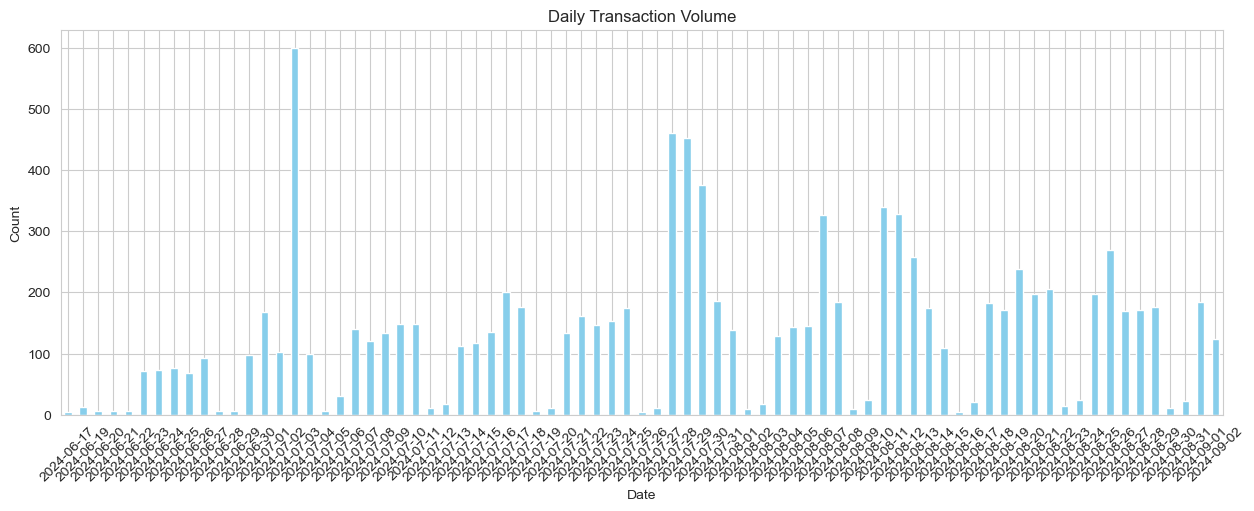


Busiest transaction days:
Transaction_Day
2024-07-03    599
2024-07-28    460
2024-07-29    453
2024-07-30    375
2024-08-11    339
Name: count, dtype: int64


In [5]:
# Cell 4: Temporal Analysis
# Daily transaction volume
daily_counts = df['Transaction_Day'].value_counts().sort_index()

plt.figure(figsize=(15, 5))
daily_counts.plot(kind='bar', color='skyblue')
plt.title('Daily Transaction Volume')
plt.xlabel('Date')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

print("\nBusiest transaction days:")
print(daily_counts.nlargest(5))

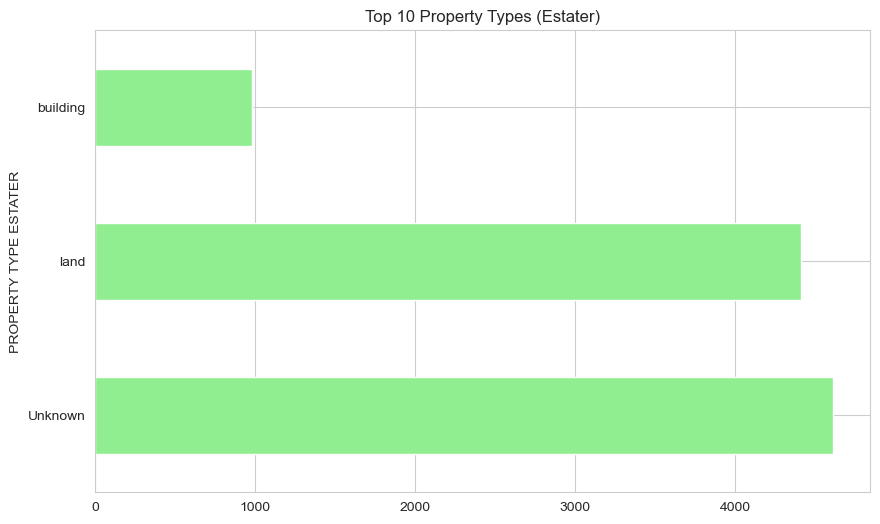


Property type comparison:


PROPERTY TYPE AS PER GOVERNMENT RECORD,Unknown,building,land
PROPERTY TYPE ESTATER,,,
Unknown,1659,0,2952
building,0,3,976
land,0,0,4410


In [6]:
# Cell 5: Property Type Analysis
plt.figure(figsize=(10, 6))
df['PROPERTY TYPE ESTATER'].value_counts().head(10).plot(kind='barh', color='lightgreen')
plt.title('Top 10 Property Types (Estater)')
plt.show()

# Compare with government records
type_comparison = pd.crosstab(df['PROPERTY TYPE ESTATER'], 
                             df['PROPERTY TYPE AS PER GOVERNMENT RECORD'])
print("\nProperty type comparison:")
display(type_comparison.head())

CONFLICTING PROPERTY TYPE ANALYSIS

Found 3928 records with conflicting property types:


,PROPERTY UID,PROPERTY TYPE ESTATER,PROPERTY TYPE AS PER GOVERNMENT RECORD
0,LRYDBK2412,building,land
17,LRYDBW9894,building,land
22,LRYDEF5345,Unknown,land
40,LRYDDE3020,Unknown,land
42,LRYDDD2249,Unknown,land


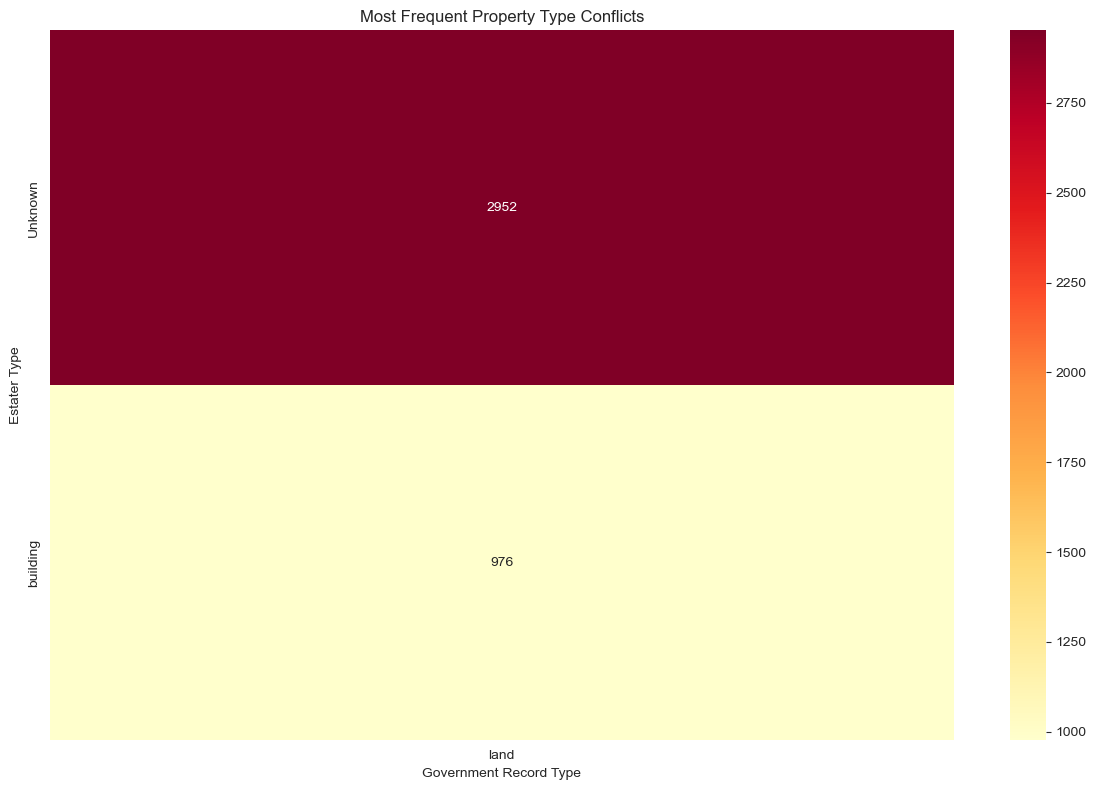


Most common conflicts:


PROPERTY TYPE ESTATER  PROPERTY TYPE AS PER GOVERNMENT RECORD
Unknown                land                                      2952
building               land                                       976
dtype: int64

In [7]:
# Cell 6: Conflicting Property Type Analysis
print("="*50)
print("CONFLICTING PROPERTY TYPE ANALYSIS")
print("="*50)

# Create flag for conflicting types
df['TYPE_CONFLICT'] = df['PROPERTY TYPE ESTATER'] != df['PROPERTY TYPE AS PER GOVERNMENT RECORD']
conflicts = df[df['TYPE_CONFLICT']]

print(f"\nFound {len(conflicts)} records with conflicting property types:")
display(conflicts[['PROPERTY UID', 'PROPERTY TYPE ESTATER', 
                  'PROPERTY TYPE AS PER GOVERNMENT RECORD']].head())

# Visualize most common conflicts
if not conflicts.empty:
    conflict_types = pd.crosstab(conflicts['PROPERTY TYPE ESTATER'], 
                               conflicts['PROPERTY TYPE AS PER GOVERNMENT RECORD'])
    
    plt.figure(figsize=(12, 8))
    sns.heatmap(conflict_types, annot=True, fmt='d', cmap='YlOrRd')
    plt.title('Most Frequent Property Type Conflicts')
    plt.xlabel('Government Record Type')
    plt.ylabel('Estater Type')
    plt.tight_layout()
    plt.show()
    
    print("\nMost common conflicts:")
    display(conflict_types.stack().sort_values(ascending=False).head(10))
else:
    print("No conflicting property types found!")

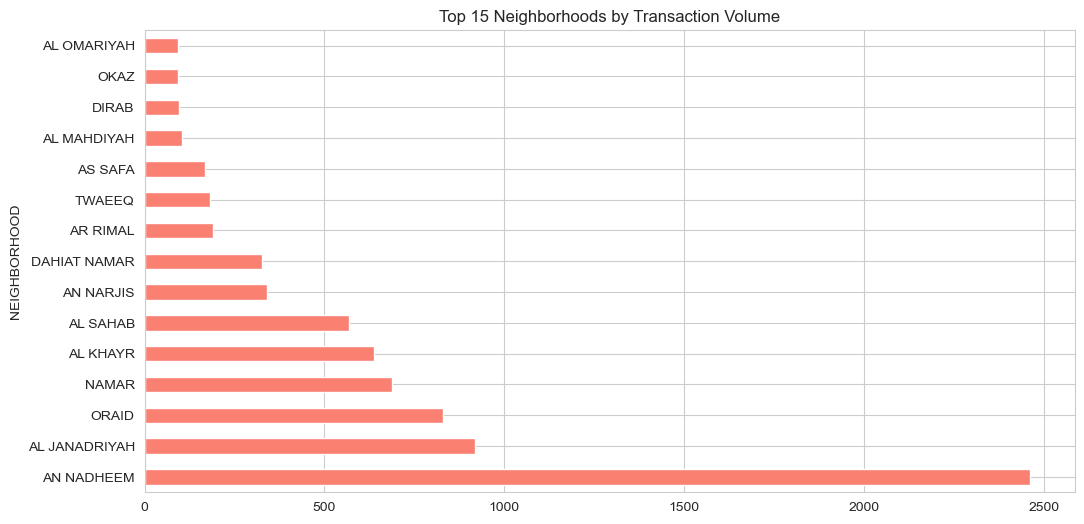


Neighborhoods with highest average price per sqm:


NEIGHBORHOOD
Al Nakhil        22596.660808
AR RAHMANIYAH    16003.038936
AL YASMEEN       13293.339965
AL MALQA         11914.580971
AR RAED          10827.464789
Name: PRICE_PER_SQM, dtype: float64

In [8]:
# Cell 7: Neighborhood Analysis
top_neighborhoods = df['NEIGHBORHOOD'].value_counts().head(15)

plt.figure(figsize=(12, 6))
top_neighborhoods.plot(kind='barh', color='salmon')
plt.title('Top 15 Neighborhoods by Transaction Volume')
plt.show()

print("\nNeighborhoods with highest average price per sqm:")
display(df.groupby('NEIGHBORHOOD')['PRICE_PER_SQM'].mean().nlargest(5))

ZONE ANALYSIS

Zone statistics (top 10 by transaction count):


VALUE (SAR)                          PRICE_PER_SQM  \
                             count          mean     median          mean   
ZONE                                                                        
Residential plots             4185  6.296048e+05   425400.0   1519.251862   
Residential Building          2773  1.609328e+06   745000.0   2427.113777   
Single family villa           1333  2.247395e+06  1118043.0   3162.384486   
Residential commercial          49  4.604186e+06  1400000.0   4949.630529   
Blank                            1  1.700000e+06  1700000.0   1942.857143   

                       TRANSACTION AREA (sqm)  
                                         mean  
ZONE                                           
Residential plots                  561.795460  
Residential Building               651.923909  
Single family villa                681.764441  
Residential commercial             897.489796  
Blank                              875.000000

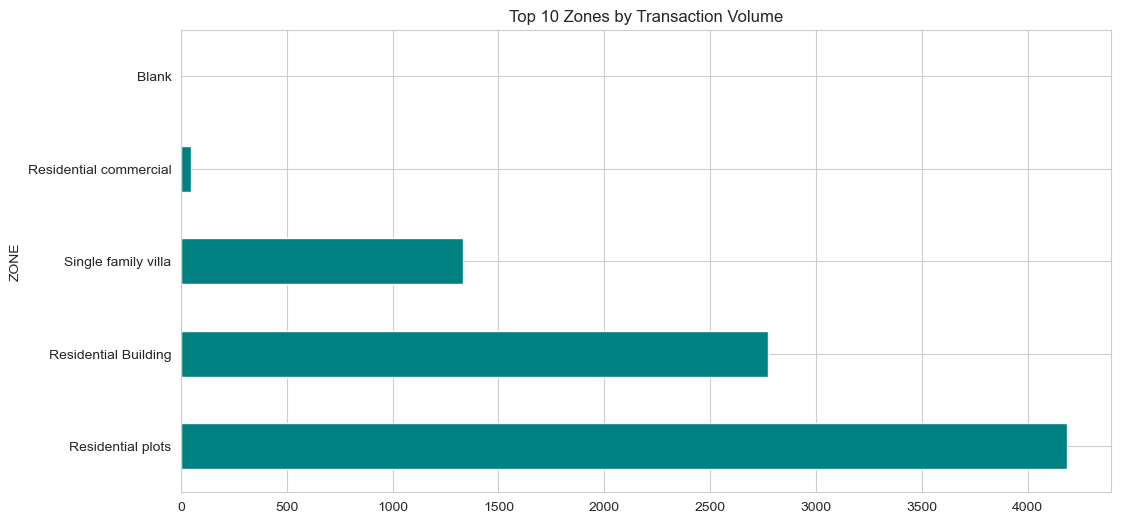

In [9]:
# Cell 8: Zone Analysis 
if 'ZONE' in df.columns and df['ZONE'].notna().any():
    print("="*50)
    print("ZONE ANALYSIS")
    print("="*50)
    
    zone_stats = df.groupby('ZONE').agg({
        'VALUE (SAR)': ['count', 'mean', 'median'],
        'PRICE_PER_SQM': 'mean',
        'TRANSACTION AREA (sqm)': 'mean'
    }).sort_values(by=('VALUE (SAR)', 'count'), ascending=False)
    
    print("\nZone statistics (top 10 by transaction count):")
    display(zone_stats.head(10))
    
    plt.figure(figsize=(12, 6))
    df['ZONE'].value_counts().head(10).plot(kind='barh', color='teal')
    plt.title('Top 10 Zones by Transaction Volume')
    plt.show()
else:
    print("No zone data available")

In [10]:
# Cell 9: Block Analysis 
if 'BLOCK' in df.columns and df['BLOCK'].notna().any():
    print("="*50)
    print("BLOCK ANALYSIS")
    print("="*50)
    
    block_stats = df.groupby('BLOCK').agg({
        'VALUE (SAR)': ['count', 'mean'],
        'PRICE_PER_SQM': 'mean'
    }).sort_values(by=('VALUE (SAR)', 'count'), ascending=False)
    
    print("\nMost active blocks (top 10):")
    display(block_stats.head(10))
    
    # Relationship between block and neighborhood
    if 'NEIGHBORHOOD' in df.columns:
        block_neighborhood = df.groupby(['BLOCK', 'NEIGHBORHOOD']).size().unstack().fillna(0)
        print("\nBlocks spanning multiple neighborhoods:")
        display(block_neighborhood[block_neighborhood.gt(0).sum(axis=1) > 1].head())
else:
    print("No block data available")

BLOCK ANALYSIS

Most active blocks (top 10):


VALUE (SAR)               PRICE_PER_SQM
                    count          mean          mean
BLOCK                                                
AN NADHEEM           2452  3.999930e+05   1062.380235
Al Janadriyah         897  7.616431e+05   1777.830243
Oraid                 724  3.800595e+05    856.323919
AL KHAYR              638  1.214176e+06   2094.857950
Al Sahab              533  4.333307e+05   1170.573329
AN NARJIS             333  3.675930e+06   5892.315454
Dahiyat Namar         326  9.858694e+05   1247.468137
AR RIMAL              184  1.690366e+06   3242.154906
TWAEEQ                168  1.300648e+06   2553.963451
AS SAFA               164  2.094638e+06   3702.983685


Blocks spanning multiple neighborhoods:


NEIGHBORHOOD,AL JANADRIYAH,AL YARMUK,AN NARJIS,Al Yarmuk,AL BADEAH,AS SUWAIDI,AL MANSURAH,AR RABWAH,An Nadheem,AT TAAWUN,...,SHUBRA,KING KHALID INT AIRPORT,SULTANAH,TAYBAH,UTAYQAH,WASTUMM AL HAMAM,WEST AL ORAIJA,WEST AN NASEEM,ZAHRAT AL EAWDT SHRQ,ZAHRIH AL EAWDAT GHARB
BLOCK,,,,,,,,,,,,,,,,,,,,,
10,2.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
13,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
14,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
20,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


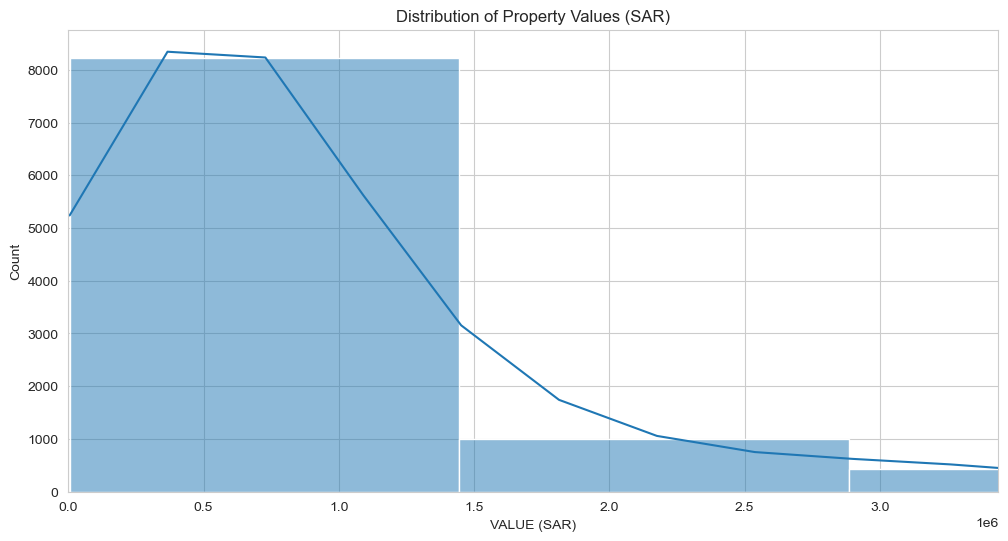


Most expensive properties:


,PROPERTY UID,VALUE (SAR),NEIGHBORHOOD
5261,NaN,72000000,IRQAH
6627,LRYDAO6200,65000000,AL MALQA
8671,NaN,55000000,HITTEEN
433,NaN,50152762,KING FAHD
3136,NaN,49140000,AT TAAWUN


In [11]:
# Cell 10: Price Distribution Analysis
plt.figure(figsize=(12, 6))
sns.histplot(df['VALUE (SAR)'], bins=50, kde=True)
plt.title('Distribution of Property Values (SAR)')
plt.xlim(0, df['VALUE (SAR)'].quantile(0.95))  # Remove extreme outliers
plt.show()

print("\nMost expensive properties:")
display(df.nlargest(5, 'VALUE (SAR)')[['PROPERTY UID', 'VALUE (SAR)', 'NEIGHBORHOOD']])

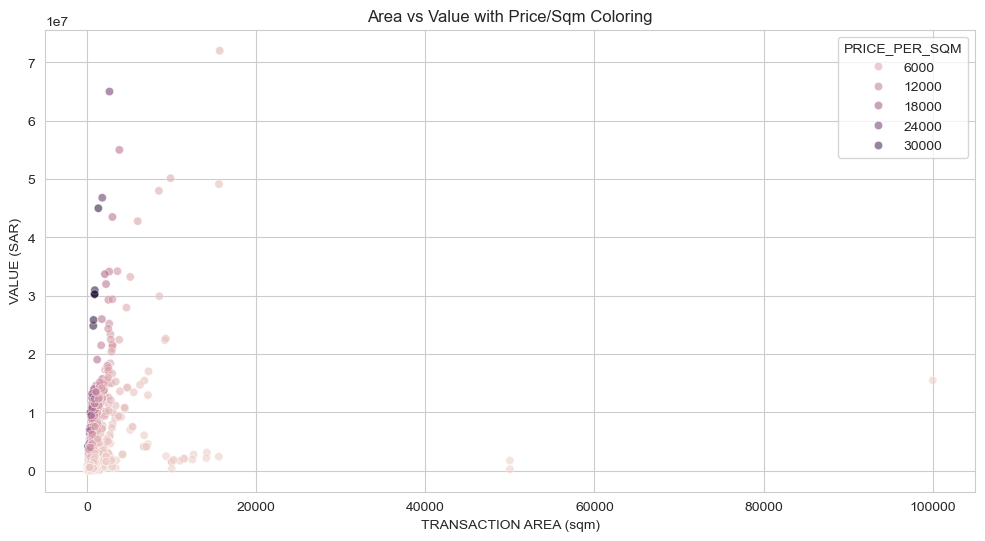


Average area by property type:


PROPERTY TYPE ESTATER
Unknown     489.376708
land        666.213832
building    972.434116
Name: TRANSACTION AREA (sqm), dtype: float64

In [12]:
# Cell 11: Area Analysis
plt.figure(figsize=(12, 6))
sns.scatterplot(x='TRANSACTION AREA (sqm)', y='VALUE (SAR)', 
                data=df, alpha=0.6, hue='PRICE_PER_SQM')
plt.title('Area vs Value with Price/Sqm Coloring')
plt.show()

print("\nAverage area by property type:")
display(df.groupby('PROPERTY TYPE ESTATER')['TRANSACTION AREA (sqm)'].mean().sort_values())

In [13]:
# Cell 12: Transaction Source Analysis
if 'TRANSACTION SOURCE' in df.columns and df['TRANSACTION SOURCE'].notna().any():
    print("="*50)
    print("TRANSACTION SOURCE ANALYSIS")
    print("="*50)
    
    source_counts = df['TRANSACTION SOURCE'].value_counts()
    
    plt.figure(figsize=(10, 5))
    source_counts.plot(kind='bar', color='purple')
    plt.title('Transaction Sources Distribution')
    plt.xticks(rotation=45)
    plt.show()
    
    print("\nAverage price per sqm by source:")
    display(df.groupby('TRANSACTION SOURCE')['PRICE_PER_SQM'].mean().sort_values(ascending=False))
else:
    print("No transaction source data available")

No transaction source data available



Found 1175 statistical outliers:


,PROPERTY UID,PRICE_PER_SQM,NEIGHBORHOOD
1,NaN,3883.495146,AL HAZM
8,NaN,5000.000000,Industrial Area
17,LRYDBW9894,4400.000000,AR RABWAH
22,LRYDEF5345,5694.444444,AL KHALEEJ
37,LRYDDO8684,4628.985507,TWAEEQ


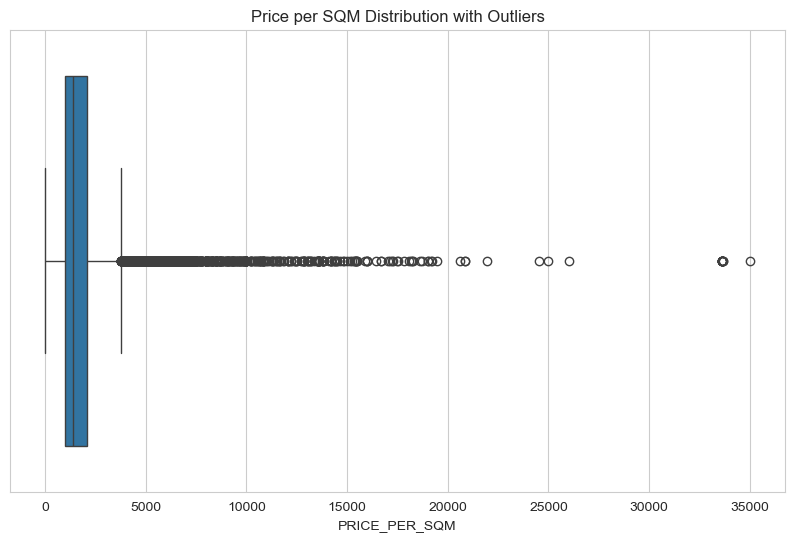

In [14]:
# Cell 13: Outlier Detection
# Statistical outliers
Q1 = df['PRICE_PER_SQM'].quantile(0.25)
Q3 = df['PRICE_PER_SQM'].quantile(0.75)
IQR = Q3 - Q1
stat_outliers = df[
    (df['PRICE_PER_SQM'] < (Q1 - 1.5*IQR)) | 
    (df['PRICE_PER_SQM'] > (Q3 + 1.5*IQR))
]

print(f"\nFound {len(stat_outliers)} statistical outliers:")
display(stat_outliers[['PROPERTY UID', 'PRICE_PER_SQM', 'NEIGHBORHOOD']].head())

# Visualize outliers
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['PRICE_PER_SQM'])
plt.title('Price per SQM Distribution with Outliers')
plt.show()

OUTLIER DEEP DIVE

Total unique outliers identified: 1369

Breakdown of outliers:


NEIGHBORHOOD
AN NARJIS                  319
HITTEEN                     71
AL KHAYR                    71
AL OMARIYAH                 67
AL MALQA                    53
AL YASMEEN                  43
AL MAHDIYAH                 42
AS SAFA                     41
AR RIMAL                    34
KING KHALID INT AIRPORT     31
dtype: int64

C:\Users\anupr\AppData\Local\Temp\ipykernel_13388\2688313314.py:25: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


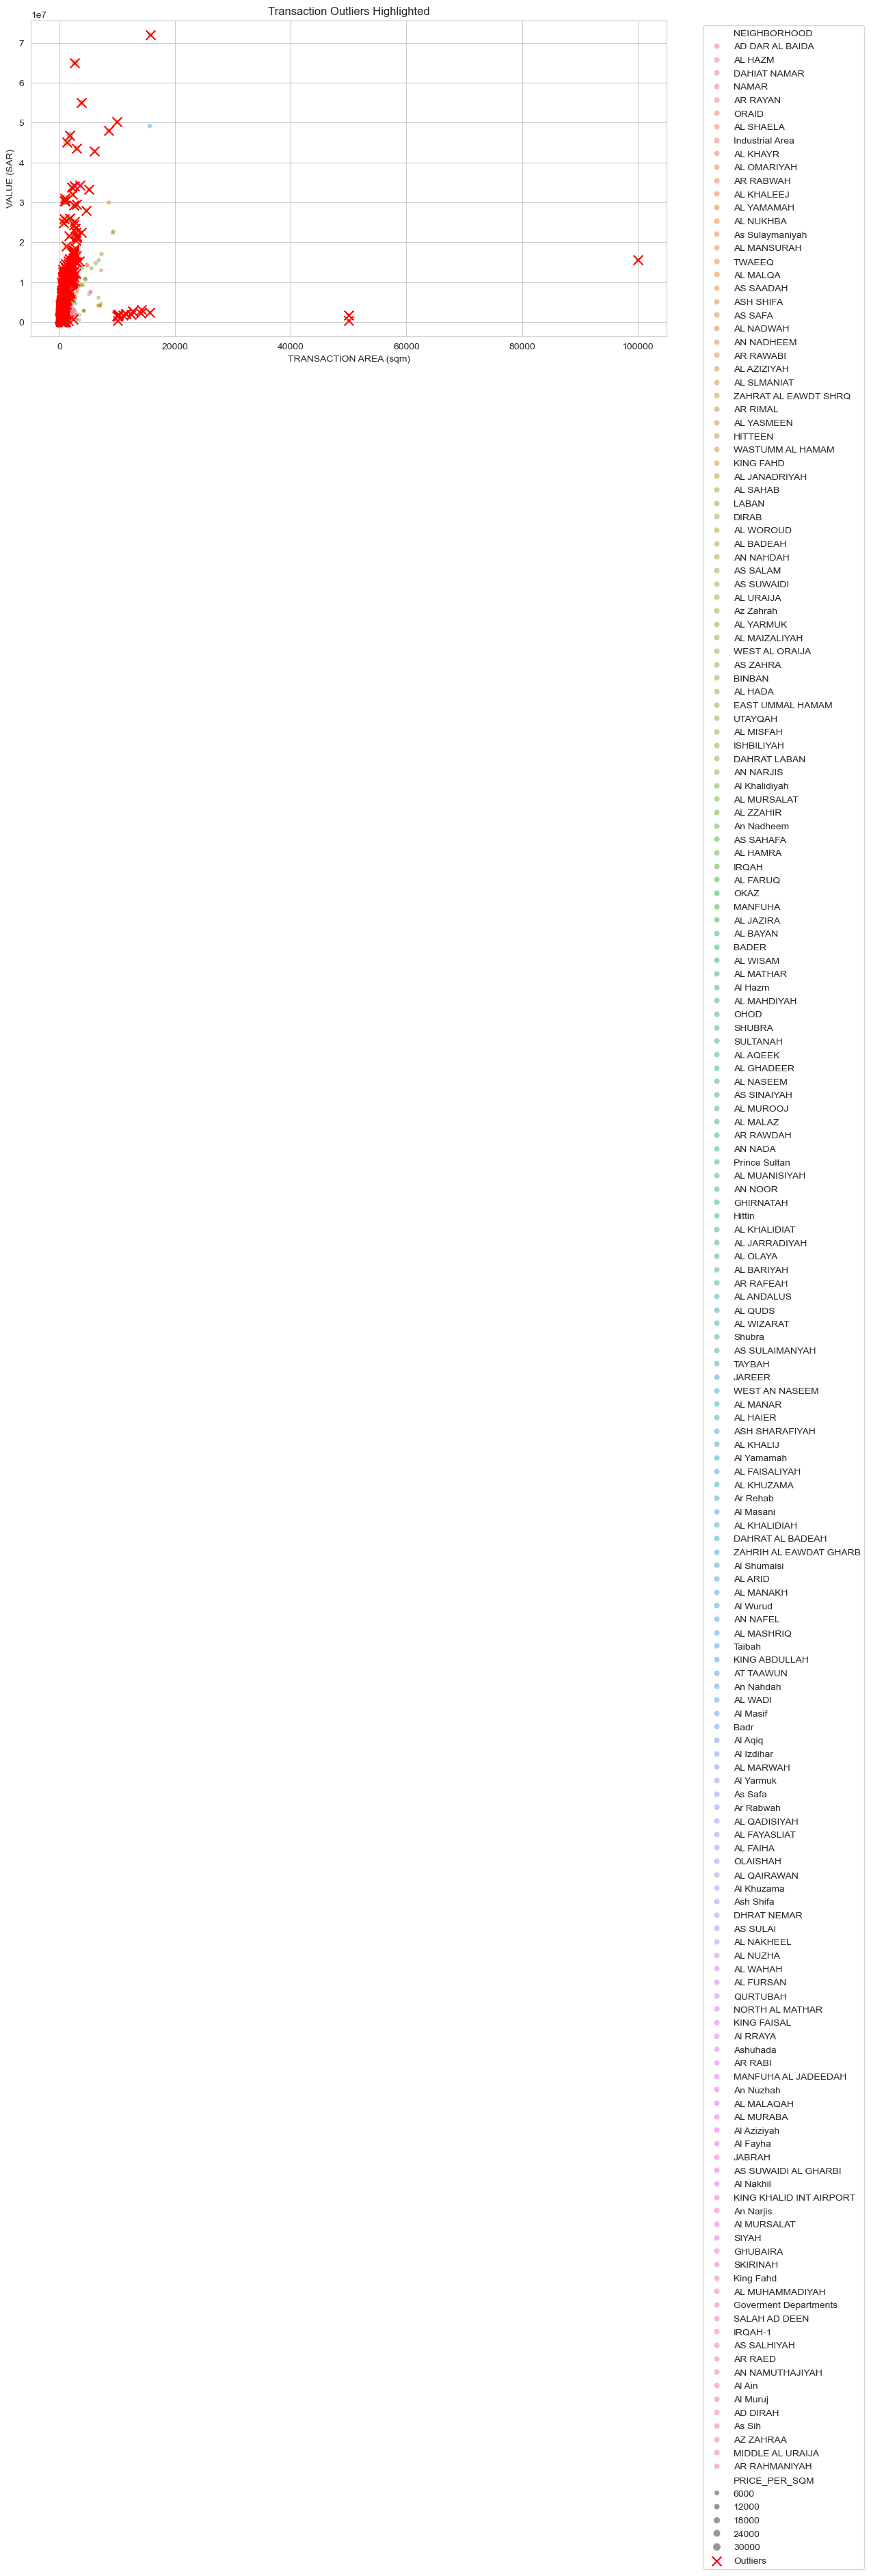

In [15]:
# Cell 14: Outlier Deep Dive
print("="*50)
print("OUTLIER DEEP DIVE")
print("="*50)

if 'OUTLIER' in df.columns:
    system_outliers = df[df['OUTLIER'] == 'Yes']
    combined_outliers = pd.concat([stat_outliers, system_outliers]).drop_duplicates()
    
    print(f"\nTotal unique outliers identified: {len(combined_outliers)}")
    print("\nBreakdown of outliers:")
    outlier_summary = combined_outliers.groupby('NEIGHBORHOOD').size().sort_values(ascending=False)
    display(outlier_summary.head(10))
    
    # Visualize outlier characteristics
    plt.figure(figsize=(12, 6))
    sns.scatterplot(x='TRANSACTION AREA (sqm)', y='VALUE (SAR)',
                    hue='NEIGHBORHOOD', size='PRICE_PER_SQM',
                    data=df, alpha=0.5)
    plt.scatter(x=combined_outliers['TRANSACTION AREA (sqm)'], 
                y=combined_outliers['VALUE (SAR)'],
                color='red', marker='x', s=100, label='Outliers')
    plt.title('Transaction Outliers Highlighted')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
else:
    print("No system-flagged outliers column found")

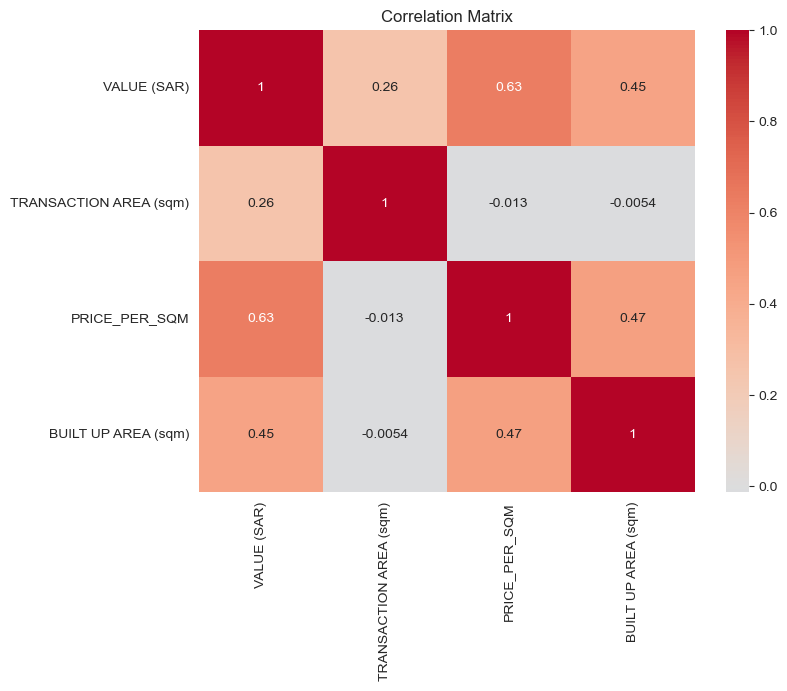

In [16]:
# Cell 15: Correlation Analysis
numeric_cols = ['VALUE (SAR)', 'TRANSACTION AREA (sqm)', 'PRICE_PER_SQM']
if 'BUILT UP AREA (sqm)' in df.columns:
    numeric_cols.append('BUILT UP AREA (sqm)')

corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

TRANSACTION RATE VALIDATION

Found 1120 records with rate discrepancies > 1 SAR/sqm:


,PROPERTY UID,PROPERTY TRANSACTION RATE (SAR/sqm),CALCULATED_RATE,NEIGHBORHOOD
1,NaN,3891.1,3883.495146,AL HAZM
10,LRYDAK2180,1698.6,1697.530864,AL KHAYR
12,LRYDBO8152,3000.0,2996.231156,AL OMARIYAH
13,LRYDCS2663,672.0,670.926518,ORAID
20,LRYDAF2542,2117.4,2118.644068,AL KHAYR


C:\Users\anupr\AppData\Local\Temp\ipykernel_13388\2086135009.py:22: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


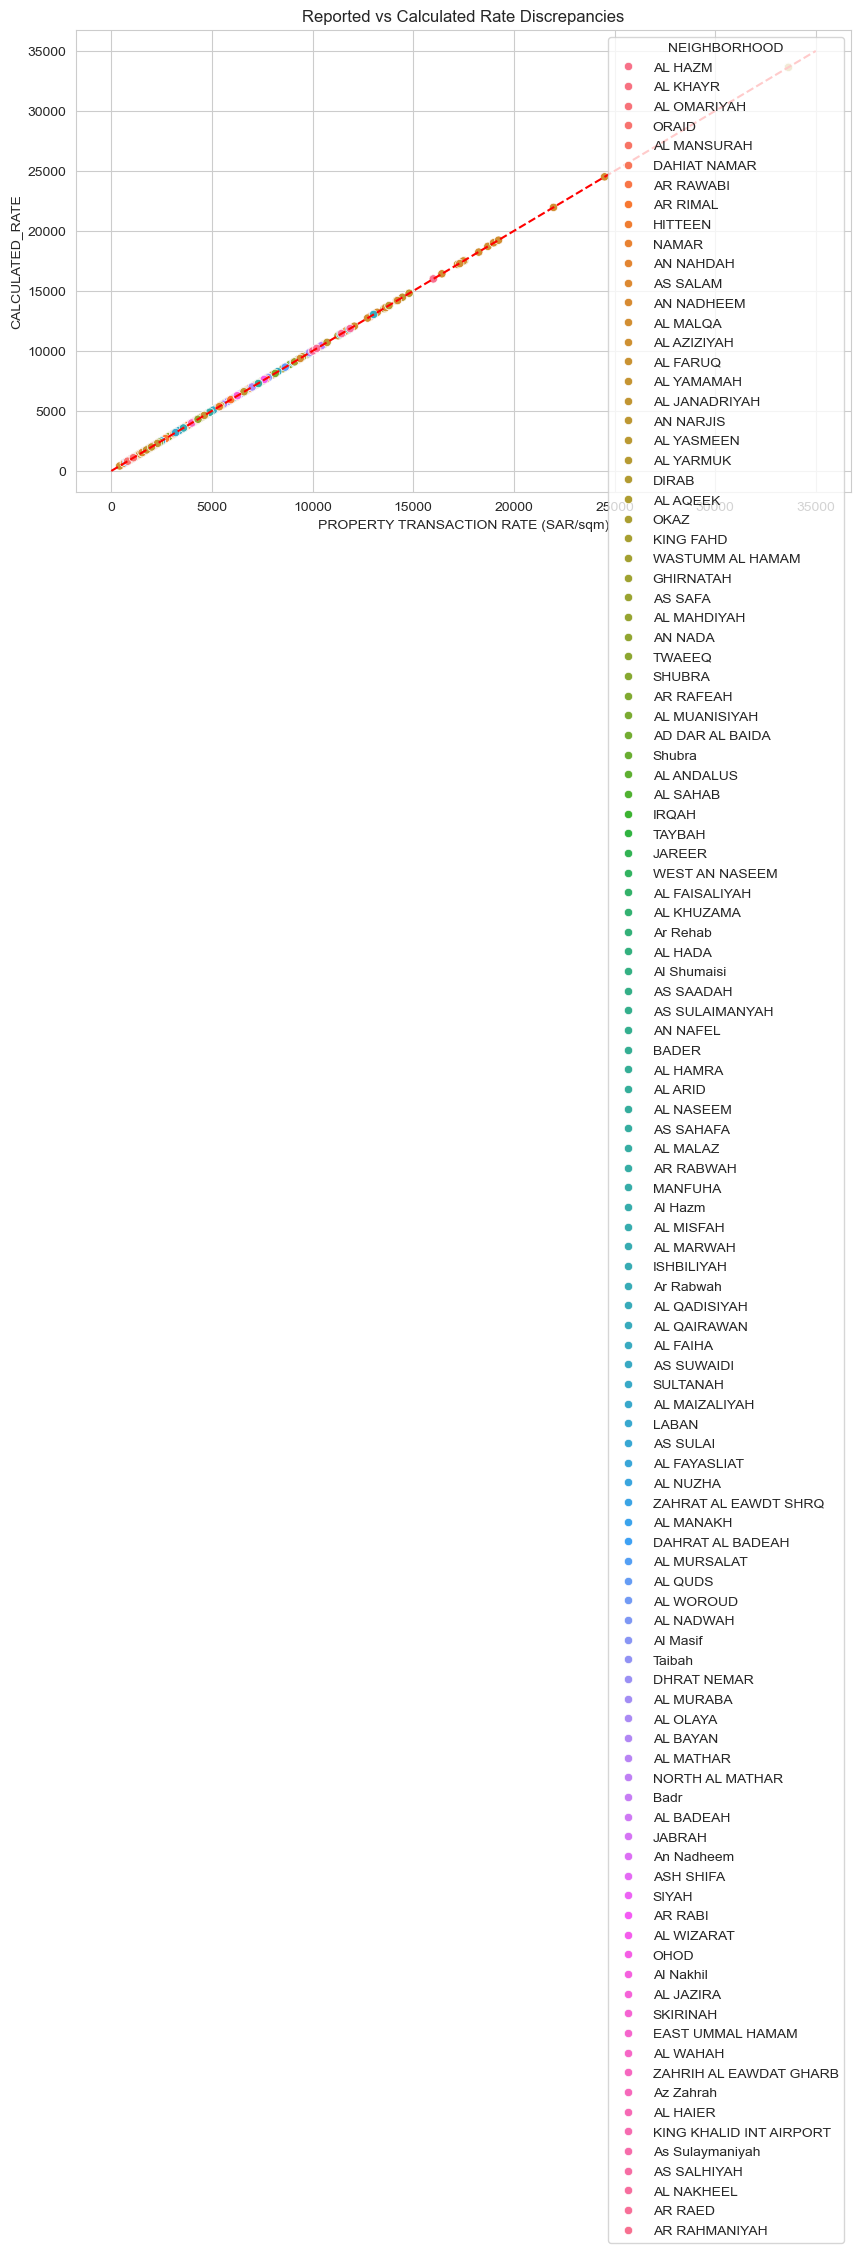

In [17]:
# Cell 16: Transaction Rate Validation
print("="*50)
print("TRANSACTION RATE VALIDATION")
print("="*50)

# Check if calculated rate matches provided rate
df['CALCULATED_RATE'] = df['VALUE (SAR)'] / df['TRANSACTION AREA (sqm)']
rate_discrepancy = df[abs(df['PROPERTY TRANSACTION RATE (SAR/sqm)'] - df['CALCULATED_RATE']) > 1]

print(f"\nFound {len(rate_discrepancy)} records with rate discrepancies > 1 SAR/sqm:")
display(rate_discrepancy[['PROPERTY UID', 'PROPERTY TRANSACTION RATE (SAR/sqm)', 
                         'CALCULATED_RATE', 'NEIGHBORHOOD']].head())

if not rate_discrepancy.empty:
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x='PROPERTY TRANSACTION RATE (SAR/sqm)', y='CALCULATED_RATE',
                    data=rate_discrepancy, hue='NEIGHBORHOOD')
    plt.plot([0, df['PROPERTY TRANSACTION RATE (SAR/sqm)'].max()], 
             [0, df['PROPERTY TRANSACTION RATE (SAR/sqm)'].max()], 
             'r--')
    plt.title('Reported vs Calculated Rate Discrepancies')
    plt.tight_layout()
    plt.show()

BUILT-UP AREA ANALYSIS


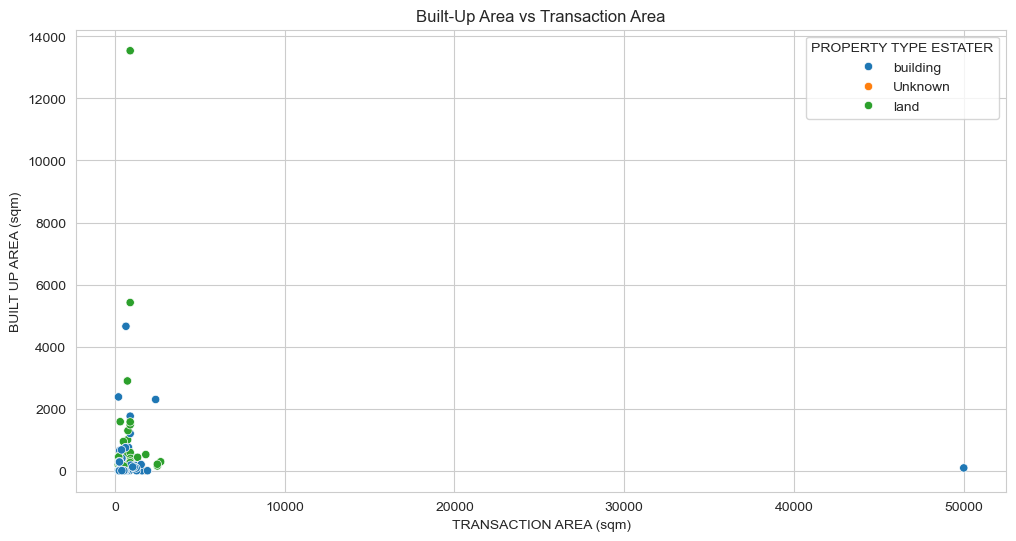


Utilization ratio by property type:


PROPERTY TYPE ESTATER
building    0.563712
Unknown     0.642456
land        1.148604
Name: UTILIZATION_RATIO, dtype: float64

In [18]:
# Cell 17: Built-Up Area Analysis (if available)
if 'BUILT UP AREA (sqm)' in df.columns:
    print("="*50)
    print("BUILT-UP AREA ANALYSIS")
    print("="*50)
    
    df['UTILIZATION_RATIO'] = df['BUILT UP AREA (sqm)'] / df['TRANSACTION AREA (sqm)']
    
    plt.figure(figsize=(12, 6))
    sns.scatterplot(x='TRANSACTION AREA (sqm)', y='BUILT UP AREA (sqm)',
                    hue='PROPERTY TYPE ESTATER', data=df)
    plt.title('Built-Up Area vs Transaction Area')
    plt.show()
    
    print("\nUtilization ratio by property type:")
    display(df.groupby('PROPERTY TYPE ESTATER')['UTILIZATION_RATIO'].mean().sort_values())
else:
    print("No built-up area data available")

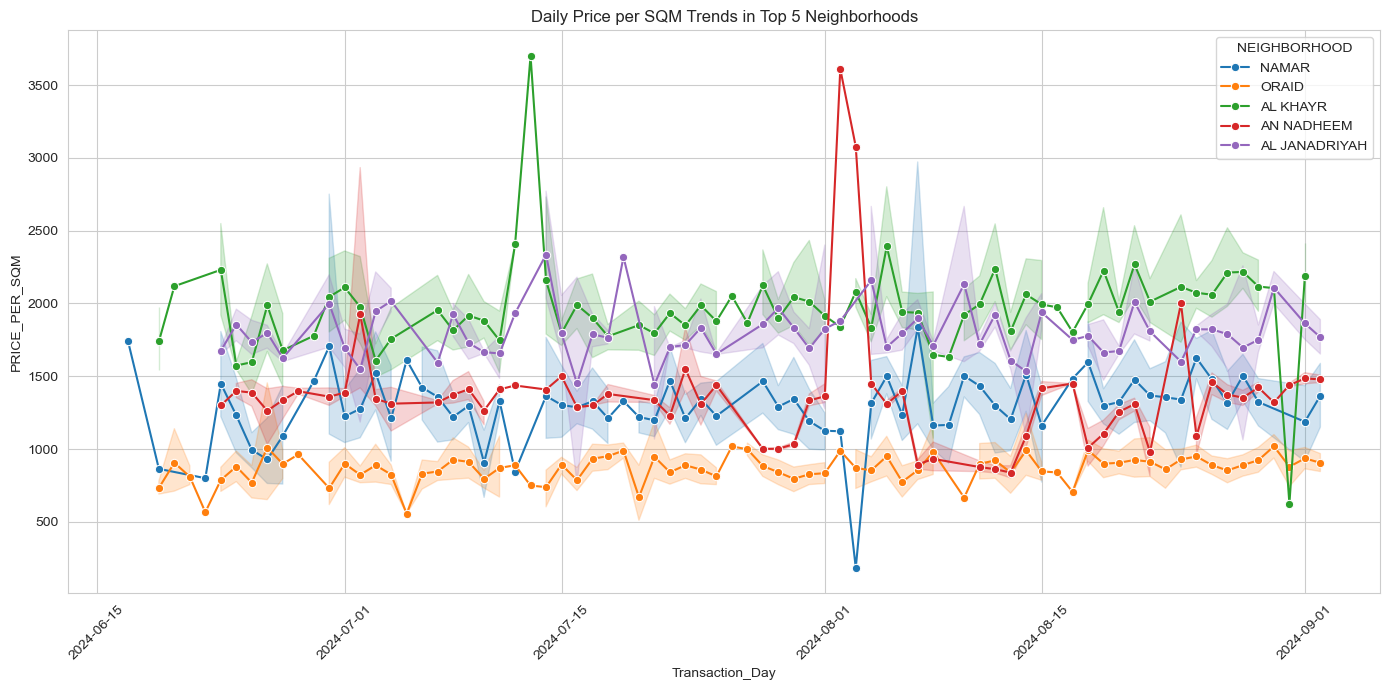

In [19]:
# Cell 18: Advanced Visualization - Price Trends by Neighborhood
top_5_neighborhoods = df['NEIGHBORHOOD'].value_counts().nlargest(5).index.tolist()
filtered_df = df[df['NEIGHBORHOOD'].isin(top_5_neighborhoods)]

plt.figure(figsize=(14, 7))
sns.lineplot(x='Transaction_Day', y='PRICE_PER_SQM', 
             hue='NEIGHBORHOOD', data=filtered_df, marker='o')
plt.title('Daily Price per SQM Trends in Top 5 Neighborhoods')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

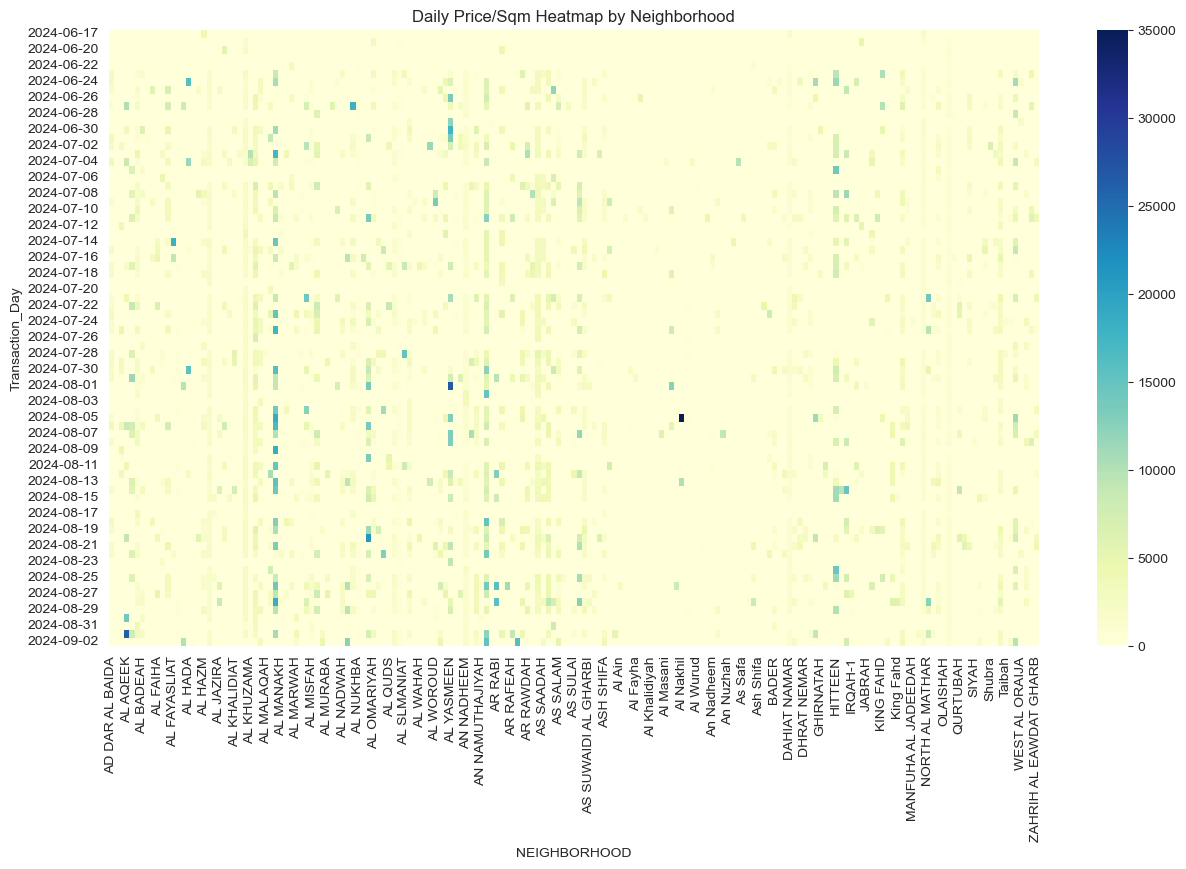

In [20]:
# Cell 19: Temporal Patterns by Neighborhood
pivot = df.pivot_table(index='Transaction_Day', 
                      columns='NEIGHBORHOOD', 
                      values='PRICE_PER_SQM', 
                      aggfunc='mean')

plt.figure(figsize=(15, 8))
sns.heatmap(pivot.fillna(0), cmap='YlGnBu')
plt.title('Daily Price/Sqm Heatmap by Neighborhood')
plt.show()

In [25]:
# Cell 20: Export Results
# Save cleaned data
df.to_excel('cleaned_property_data.xlsx', index=False)

# Save summary statistics
summary_stats = df.describe(include='all').transpose()
# Export summary as CSV with UTF-8 encoding
summary_stats.to_csv('property_summary_stats.csv', encoding='utf-8-sig', index=True)

#summary_stats.to_excel('property_summary_stats.xlsx', engine='openpyxl', index=True)

print("Analysis complete! Data exported to Excel files.")

Analysis complete! Data exported to Excel files.
